# Support Operations Analytics — Summit Office Solutions (simulated data)
**Goal:** act as the Business Analyst for a customer-support center that services copiers, printers and managed IT.
Measure process effectiveness, find the biggest improvement opportunities, and build a business case.

**Data:** 48,000 simulated support tickets (Oct 2025 – Sep 2026). The data is synthetic and was generated by
`src/generate_data.py`; no real company data is used.

**Workflow:** 1) validate & clean → 2) load to SQLite and compute KPIs in SQL → 3) analyze trends and root causes in
pandas/NumPy → 4) quantify the business case → 5) export a stakeholder workbook and run validation tests.

In [1]:
import sys, warnings; sys.path.insert(0, '../src'); warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from pipeline import load_raw, clean, load_sqlite, kpis, run_sql, named_queries
pd.set_option('display.float_format', '{:,.3f}'.format)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
FIG = '../reports/figures/'

## 1. Data validation & cleaning
Every fix is counted so the cleaning step is auditable.

In [2]:
raw = load_raw()
df, dq = clean(raw)
pd.Series(dq, name='value').to_frame()

,value
rows_in,"48,025.000"
duplicate_rows,25.000
region_case_fixes,20.000
negative_handle_time_fixed,15.000
resolved_before_created,0.000
null_ticket_ids,0.000
csat_response_rate,0.352
rows_out,"48,000.000"


## 2. Load to SQLite and compute KPIs with SQL
The query library lives in `sql/kpi_queries.sql` (window functions, joins, ranking).

In [3]:
load_sqlite(df)
Q = named_queries()
summary = run_sql(Q['kpi_summary'])
summary.T.rename(columns={0: 'value'})

,value
tickets,"48,000.000"
sla_attainment,0.877
first_contact_resolution,0.562
avg_first_response_min,39.840
avg_handle_time_min,10.790
reopen_rate,0.053
avg_csat,4.130
cost_per_ticket,36.940


In [4]:
# Cross-check: SQL and pandas must agree (this is also enforced in tests/)
k = kpis(df)
assert abs(k['sla_attainment'] - summary.sla_attainment[0]) < 1e-4
assert k['tickets'] == summary.tickets[0]
print('SQL and pandas KPIs reconcile ✔')

SQL and pandas KPIs reconcile ✔


## 3. Trends

,month,tickets,sla_attainment,fcr,reopen_rate,avg_csat,volume_mom_pct
0,2025-10,4165,0.877,0.568,0.052,4.130,NaN
1,2025-11,3830,0.877,0.567,0.052,4.130,-8.000
2,2025-12,4276,0.875,0.557,0.048,4.150,11.600
3,2026-01,4037,0.876,0.557,0.049,4.110,-5.600
4,2026-02,3645,0.878,0.557,0.055,4.090,-9.700
5,2026-03,4148,0.874,0.557,0.062,4.110,13.800
6,2026-04,3967,0.873,0.578,0.066,4.100,-4.400
7,2026-05,3910,0.879,0.555,0.055,4.130,-1.400
8,2026-06,4123,0.881,0.551,0.052,4.120,5.400
9,2026-07,4063,0.875,0.563,0.047,4.120,-1.500


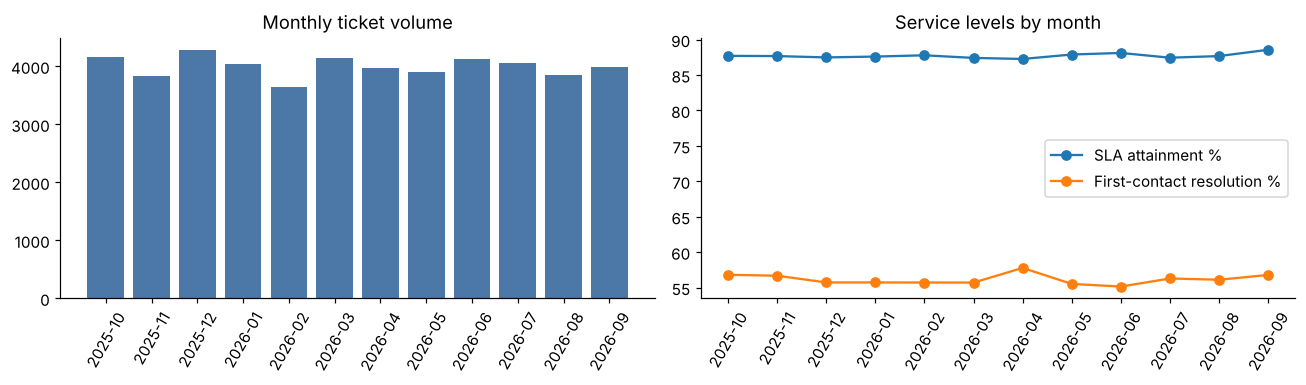

In [5]:
trend = run_sql(Q['monthly_trend'])
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].bar(trend.month, trend.tickets, color='#4C78A8'); ax[0].set_title('Monthly ticket volume'); ax[0].tick_params(axis='x', rotation=60)
ax[1].plot(trend.month, trend.sla_attainment*100, marker='o', label='SLA attainment %')
ax[1].plot(trend.month, trend.fcr*100, marker='o', label='First-contact resolution %')
ax[1].set_title('Service levels by month'); ax[1].legend(); ax[1].tick_params(axis='x', rotation=60)
plt.tight_layout(); plt.savefig(FIG+'01_trends.png', bbox_inches='tight'); trend

## 4. Finding #1 — Simple requests are clogging the live-agent queue

,category,channel,tickets,agent_hours,agent_cost_usd
0,Meter Read / Billing,Email,1220,140.900,"7,186.000"
1,Meter Read / Billing,Phone,3932,557.100,"28,410.000"
2,Toner / Supplies Reorder,Email,2025,188.000,"9,588.000"
3,Toner / Supplies Reorder,Phone,6186,718.300,"36,634.000"


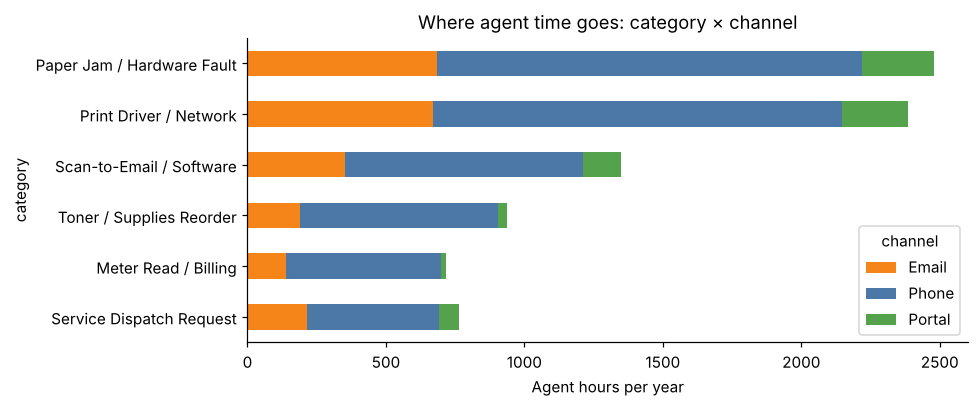

In [6]:
mix = run_sql(Q['category_channel_mix'])
pivot = mix.pivot_table(index='category', columns='channel', values='agent_hours', aggfunc='sum').fillna(0)
ax = pivot.sort_values('Phone').plot.barh(stacked=True, figsize=(9, 3.8), color=['#F58518', '#4C78A8', '#54A24B'])
ax.set_xlabel('Agent hours per year'); ax.set_title('Where agent time goes: category × channel')
plt.tight_layout(); plt.savefig(FIG+'02_agent_hours_mix.png', bbox_inches='tight')
defl = run_sql(Q['deflection_opportunity']); defl

In [7]:
portal_auto = df[df.simple_request & (df.channel == 'Portal')]
print(f"Portal handles simple requests in {portal_auto.handle_time_min.mean():.1f} agent-min on average "
      f"with {portal_auto.first_contact_resolved.mean():.0%} first-contact resolution")
print(f"Same requests by phone/email: {df[df.simple_request & df.channel.isin(['Phone','Email'])].handle_time_min.mean():.1f} min")

Portal handles simple requests in 1.0 agent-min on average with 94% first-contact resolution
Same requests by phone/email: 7.2 min


## 5. Finding #2 — Monday 8–11 am backlog drives SLA breaches

Monday 8-11am breach rate 20.1% vs other weekday business hours 11.6%


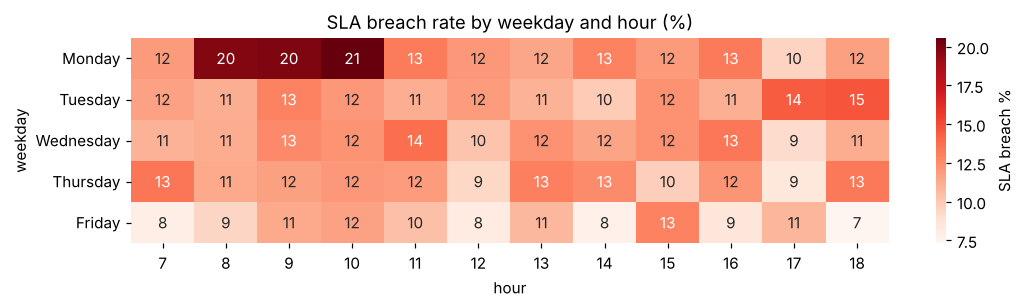

In [8]:
heat = run_sql(Q['sla_breach_heatmap'])
order = ['Monday','Tuesday','Wednesday','Thursday','Friday']
hm = heat[heat.weekday.isin(order)].pivot(index='weekday', columns='hour', values='breach_rate').loc[order]
plt.figure(figsize=(10, 2.9)); sns.heatmap(hm*100, cmap='Reds', annot=True, fmt='.0f', cbar_kws={'label': 'SLA breach %'})
plt.title('SLA breach rate by weekday and hour (%)'); plt.tight_layout(); plt.savefig(FIG+'03_breach_heatmap.png', bbox_inches='tight')
mon = df[(df.weekday=='Monday') & df.hour.between(8,10)]
rest = df[~((df.weekday=='Monday') & df.hour.between(8,10)) & df.hour.between(7,18) & (df.created_at.dt.weekday<5)]
print(f"Monday 8-11am breach rate {1-mon.sla_met.mean():.1%} vs other weekday business hours {1-rest.sla_met.mean():.1%}")

## 6. Finding #3 — Firmware v4.2 caused a reopen spike in the Inland Empire

Upper control limit 12.7%; months flagged: ['2026-03', '2026-04', '2026-05']


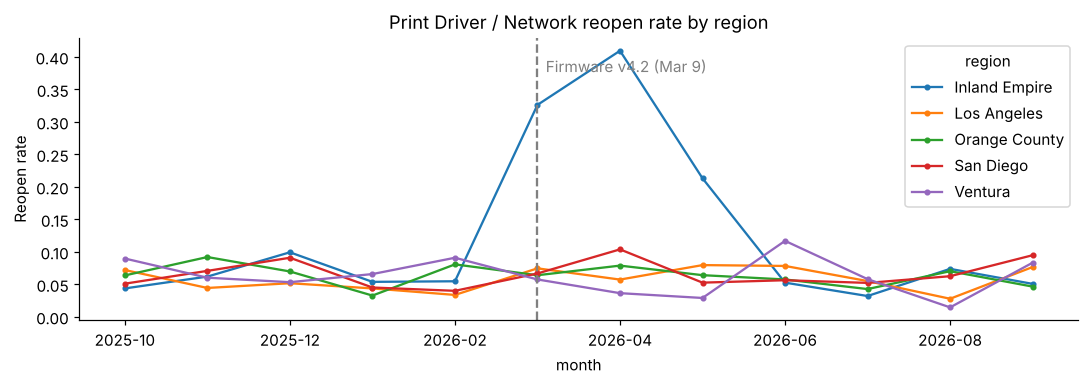

In [9]:
ro = run_sql(Q['reopen_by_region_month'])
p = ro.pivot(index='month', columns='region', values='reopen_rate')
ax = p.plot(figsize=(10, 3.6), marker='o', ms=3); ax.axvline(list(p.index).index('2026-03'), ls='--', c='grey')
ax.text(list(p.index).index('2026-03')+0.1, p.values.max()*0.92, 'Firmware v4.2 (Mar 9)', color='grey')
ax.set_ylabel('Reopen rate'); ax.set_title('Print Driver / Network reopen rate by region')
plt.tight_layout(); plt.savefig(FIG+'04_reopen_spike.png', bbox_inches='tight')
# Simple control limit: flag months > mean + 3 sigma of the region's prior 5 months
ie = p['Inland Empire']; base = ie.loc[:'2026-02']
ucl = base.mean() + 3*base.std()
print(f"Upper control limit {ucl:.1%}; months flagged:", list(ie[ie > ucl].index))

## 7. Finding #4 — P1 (critical) tickets miss SLA almost half the time

In [10]:
run_sql(Q['sla_by_priority'])

,priority,sla_target_hours,tickets,sla_attainment,avg_resolution_hours
0,P1,4,2245,0.525,5.380
1,P2,8,11161,0.722,5.230
2,P3,24,23305,0.930,6.770
3,P4,72,11289,0.992,8.460


## 8. Business case — quantified recommendations
Assumptions are stated explicitly so stakeholders can change them.

In [11]:
COST_PER_MIN, FTE_HOURS = 0.85, 1_880
# R1: self-service portal + reorder automation for supplies & meter reads
simple_live = df[df.simple_request & df.channel.isin(['Phone','Email'])]
ADOPTION = 0.60                                    # conservative share that moves to portal
portal_min = portal_auto.handle_time_min.mean()
r1_hours = ADOPTION * (simple_live.handle_time_min.sum() - len(simple_live)*portal_min) / 60
# R2: shift 3 late-shift Tier-1 agents to a 7am start on Mondays -> bring Monday-rush breaches to weekday norm
r2_tickets = len(mon) * ((1-mon.sla_met.mean()) - (1-rest.sla_met.mean()))
# R3: release gate + reopen-rate alert -> catch a firmware issue within 2 weeks instead of 10
fw = df[(df.category=='Print Driver / Network') & (df.region=='Inland Empire') & df.month.isin(['2026-03','2026-04','2026-05'])]
excess_reopens = len(fw) * (fw.reopened.mean() - base.mean())
r3_avoidable = excess_reopens * (1 - 2/10)
avg_cost = df[df.category=='Print Driver / Network'].cost_usd.mean()

case = pd.DataFrame([
  ['R1 Self-service portal for supplies & meter reads', f'{len(simple_live):,} live-agent tickets/yr',
   f'{r1_hours:,.0f} agent hrs (~{r1_hours/FTE_HOURS:.1f} FTE)', f'${r1_hours*60*COST_PER_MIN:,.0f}/yr'],
  ['R2 Monday 7am shift realignment (no new headcount)', f'{len(mon):,} Monday-rush tickets/yr',
   f'{r2_tickets:,.0f} fewer SLA breaches/yr', 'Cost-neutral'],
  ['R3 Firmware release gate + reopen alert', f'{excess_reopens:,.0f} excess reopens in 3 months',
   f'{r3_avoidable:,.0f} reopens avoidable', f'${r3_avoidable*avg_cost:,.0f} per incident'],
  ['R4 P1 fast-track dispatch path', f"{(df.priority=='P1').sum():,} P1 tickets/yr",
   f"P1 SLA {df[df.priority=='P1'].sla_met.mean():.0%} → target 80%", 'Customer retention'],
], columns=['Recommendation', 'Scope', 'Impact', 'Value'])
case

,Recommendation,Scope,Impact,Value
0,R1 Self-service portal for supplies & meter reads,"13,363 live-agent tickets/yr",830 agent hrs (~0.4 FTE),"$42,307/yr"
1,R2 Monday 7am shift realignment (no new headco...,"4,216 Monday-rush tickets/yr",360 fewer SLA breaches/yr,Cost-neutral
2,R3 Firmware release gate + reopen alert,94 excess reopens in 3 months,75 reopens avoidable,"$1,628 per incident"
3,R4 P1 fast-track dispatch path,"2,245 P1 tickets/yr",P1 SLA 53% → target 80%,Customer retention


## 9. Export stakeholder outputs

In [12]:
import json
out = {'kpis': {k: float(v) for k, v in kpis(df).items()}, 'data_quality': dq,
       'business_case': case.to_dict(orient='records'),
       'r1_hours': float(r1_hours), 'r1_value': float(r1_hours*60*COST_PER_MIN),
       'r2_breaches_avoided': float(r2_tickets), 'mon_breach': float(1-mon.sla_met.mean()),
       'rest_breach': float(1-rest.sla_met.mean()), 'excess_reopens': float(excess_reopens),
       'r3_avoidable': float(r3_avoidable), 'simple_live_tickets': int(len(simple_live)),
       'simple_live_hours': float(simple_live.handle_time_min.sum()/60),
       'trend': trend.to_dict(orient='records'), 'reopen_ie': ie.round(4).to_dict(),
       'heat': hm.round(4).reset_index().to_dict(orient='records'),
       'mix': pivot.round(1).reset_index().to_dict(orient='records'),
       'priority': run_sql(Q['sla_by_priority']).to_dict(orient='records')}
json.dump(out, open('../reports/results.json', 'w'), indent=1, default=str)
print('Saved reports/results.json and figures/')

Saved reports/results.json and figures/


## 10. Conclusion
* **Baseline:** 48,000 tickets, 87.7% SLA attainment, 56% first-contact resolution, 4.13/5 CSAT.
* **Biggest lever:** routing supply and meter-read requests to self-service frees roughly half an FTE a year.
* **Quick win:** a Monday shift change cuts SLA breaches without new headcount.
* **Control:** a reopen-rate alert would have caught the firmware issue in weeks, not months.
* **Next step:** pilot the portal change in one region, track the same KPIs, and compare against this baseline.